# 29 · Real-time lists on the test (work package 18)

**Work package 18** of the [applications plan](../../research/implementation_plan_applications.md), section 18.
Notebook 13 found on Dev B that rebuilding the lists **every hour** inside the two target days lifts the
time-weighted blend from 0.143 to 0.187, while the baseline rebuilt the same way stays at 0.096. That was the
largest gain of the development work, and it was never scored on the test.

Here the **frozen** time-weighted blend and the popularity baseline are rebuilt every hour at the 14 test points,
with the protocol of notebook 13 unchanged (`cold_start.refreshed_evaluate`): each new pick-up is judged against
the account's list from the last rebuild before it. Both are also built once per two days (the main protocol).
Nothing is tuned. Results come from `src/scripts/build_realtime.py`.

**Criterion (stated in the plan before the run):** on the 14 test points, (a) the hourly blend beats the hourly
baseline and (b) the hourly blend beats the same blend built once per two days; for both, the mean paired
difference is positive with a 95% bootstrap interval over points that excludes zero.

In [1]:
import sys

sys.path.append("../scripts")

import matplotlib.pyplot as plt
import pandas as pd

import plots
import protocol as pc
import stats

plots.style()
pd.set_option("display.float_format", "{:,.3f}".format)
table = pd.read_csv(pc.RESULTS_DIR / "wp18" / "per_point_test.csv", parse_dates=["point"])
print(f"{table['point'].nunique()} test points, {table['users'].iloc[0]:,} evaluated accounts at the first")
table.pivot_table(index="model", columns="refresh_hours", values=["recall", "cold_reached"], aggfunc="mean")

14 test points, 5,456 evaluated accounts at the first


cold_reached       recall      
refresh_hours                 1     48     1     48
model                                              
baseline                   0.000 0.000  0.111 0.108
time-weighted blend        0.107 0.000  0.194 0.151

The two-day rows reproduce the scored test (baseline 0.108, time-weighted blend 0.151), which checks that this run
uses the same protocol and models.

## 1. The criterion

In [2]:
def series(model: str, hours: int) -> pd.DataFrame:
    """Per-point recall of one model at one rebuild interval."""
    return table[(table["model"] == model) & (table["refresh_hours"] == hours)][["point", "recall"]].reset_index(drop=True)


hourly_blend, hourly_base = series("time-weighted blend", 1), series("baseline", 1)
once_blend, once_base = series("time-weighted blend", 48), series("baseline", 48)
checks = {
    "(a) hourly blend vs hourly baseline": stats.compare({"base": hourly_base, "model": hourly_blend}, baseline="base"),
    "(b) hourly blend vs the blend built once": stats.compare({"base": once_blend, "model": hourly_blend}, baseline="base"),
    "(alongside) hourly blend vs the scored baseline": stats.compare({"base": once_base, "model": hourly_blend}, baseline="base"),
}
result = pd.concat({name: c.set_index("model").loc[["model"]] for name, c in checks.items()}).droplevel(1)
result[["mean", "mean_difference", "interval_low", "interval_high", "wins", "sign_test_p"]]

,mean,mean_difference,interval_low,interval_high,wins,sign_test_p
(a) hourly blend vs hourly baseline,0.194,0.083,0.070,0.099,14 of 14,0.000
(b) hourly blend vs the blend built once,0.194,0.044,0.032,0.057,14 of 14,0.000
(alongside) hourly blend vs the scored baseline,0.194,0.086,0.072,0.102,14 of 14,0.000


In [3]:
met = all(result.loc[name, "interval_low"] > 0 for name in list(checks)[:2])
print(f"Criterion (a) and (b): {'MET' if met else 'NOT met'}")
gain = hourly_blend["recall"].mean() / once_base["recall"].mean()
print(f"Hourly blend {hourly_blend['recall'].mean():.3f} against the scored baseline {once_base['recall'].mean():.3f}: {gain:.2f} times as many new tokens found")

Criterion (a) and (b): MET
Hourly blend 0.194 against the scored baseline 0.108: 1.79 times as many new tokens found


## 2. Per point

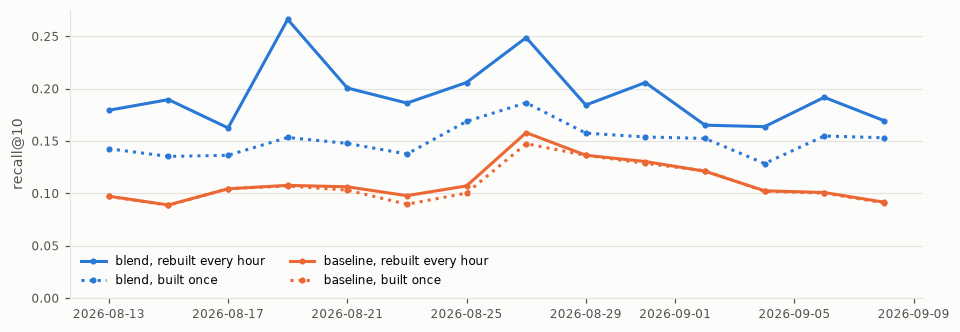

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.4))
for (label, frame), colour, style in zip(
    [("blend, rebuilt every hour", hourly_blend), ("blend, built once", once_blend), ("baseline, rebuilt every hour", hourly_base), ("baseline, built once", once_base)],
    [plots.SERIES[0], plots.SERIES[0], plots.SERIES[1], plots.SERIES[1]], ["-", ":", "-", ":"],
):  # fmt: skip
    ax.plot(frame["point"], frame["recall"], marker="o", markersize=3, color=colour, linestyle=style, label=label)
ax.set_ylim(bottom=0)
ax.set_ylabel("recall@10")
ax.legend(ncol=2, fontsize=8)
plt.show()

## 3. Cold pairs reached

The share of pick-ups of tokens that did not exist at $t$ that were on the account's list when it picked them up.

In [5]:
table.pivot_table(index="model", columns="refresh_hours", values="cold_reached", aggfunc="mean")

refresh_hours,1,48
model,,
baseline,0.000,0.000
time-weighted blend,0.107,0.000


## 4. What this shows

- **The criterion is met, and the Dev B gain carries over in full.** Rebuilt every hour, the frozen time-weighted
  blend reaches recall@10 **0.194** on the test, against 0.111 for popularity rebuilt the same way (+0.083, interval
  +0.070 to +0.099) and 0.151 for the same blend built once per two days (+0.044, +0.032 to +0.057). Both comparisons
  are won at all 14 test points. On Dev B the same numbers were 0.187, 0.096 and 0.143.
- **Against the scored baseline** (popularity built once, 0.108), the hourly lists find **1.8 times** as many of
  the tokens traders pick up next.
- **Popularity gains almost nothing from refreshing** (0.108 to 0.111): what moves within two days is each account's
  own trading, and only the personalized lists react to it. They also reach 10.7% of the pick-ups of tokens that did
  not exist at $t$, which no list made at $t$ can.
- **Nothing was tuned on the test:** settings frozen before the test, protocol of notebook 13, one run.